<a href="https://colab.research.google.com/github/www-fidezDAE/fidez.RDS/blob/main/Tukale_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

API Data Extraction

In [1]:
# Install required packages

!pip install pandas numpy scipy openpyxl pyreadstat
!pip install statsmodels matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 13.2 MB/s  0:00:00


SPSS datasets Uploading

In [10]:
from google.colab import files

uploaded = files.upload()

import os

print("Uploaded files:")

for file in os.listdir("/content"):
    if file.endswith(".sav"):
        print(file)

import pyreadstat
import pandas as pd

# Read Household Recode
hr, hr_meta = pyreadstat.read_sav("/content/SOHR71SV.sav")

# Read Individual Recode
ir, ir_meta = pyreadstat.read_sav("/content/SOIR71SV.sav")

# Read Children Recode
kr, kr_meta = pyreadstat.read_sav("/content/SOKR71SV.sav")

print("All three datasets loaded successfully.")

print("Household dataset:", hr.shape)
print("Individual dataset:", ir.shape)
print("Children dataset:", kr.shape)

print("HOUSEHOLD VARIABLES")
print(hr.columns.tolist())

print("\nINDIVIDUAL VARIABLES")
print(ir.columns.tolist())

print("\nCHILDREN VARIABLES")
print(kr.columns.tolist())

Saving SOHR71SV.sav to SOHR71SV.sav
Saving SOIR71SV.sav to SOIR71SV.sav
Saving SOKR71SV.sav to SOKR71SV.sav
Uploaded files:
SOIR71SV.sav
SOKR71SV.sav
SOHR71SV.sav
All three datasets loaded successfully.
Household dataset: (15826, 2937)
Individual dataset: (16486, 5451)
Children dataset: (21218, 559)
HOUSEHOLD VARIABLES
['HHID', 'HV000', 'HV001', 'ACTUAL_EA_CODE', 'HV002', 'HV003', 'HV005', 'HV006', 'HV007', 'HV008', 'HV009', 'HV010', 'HV011', 'HV012', 'HV013', 'HV014', 'HV015', 'HV016', 'HV017', 'HV018', 'HV020', 'HV021', 'HV023', 'HV024', 'HV025', 'HV029', 'HV030', 'HV031', 'HV032', 'HV035', 'HV041', 'HV045A', 'HV801', 'HV802', 'HV803', 'HV201', 'HV202', 'HV201A', 'HV204', 'HV205', 'HV206A', 'HV206', 'HV207', 'HV208', 'HV209', 'HV209A', 'HV210', 'HV211', 'HV212', 'HV213', 'HV214', 'HV215', 'HV216', 'HV218', 'HV219', 'HV220', 'HV221', 'HV225', 'HV226', 'HV230A', 'HV230B', 'HV232', 'HV232B', 'HV232Y', 'HV235', 'HV237', 'HV237A', 'HV237B', 'HV237C', 'HV237D', 'HV237E', 'HV237F', 'HV237X'

Study variables Indicators' Extraction

In [12]:
# ============================================================
# SOMALIA CHILD STUNTING STUDY
# SPSS DATA EXTRACTION, MERGING AND PREPARATION USING PYTHON
# GOOGLE COLAB VERSION
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import pyreadstat

from pathlib import Path
from IPython.display import display

warnings.filterwarnings("ignore")

# ============================================================
# 1. DEFINE THE GOOGLE COLAB FILE LOCATIONS
# ============================================================

data_directory = Path("/content")

required_files = {
    "HR": data_directory / "SOHR71SV.sav",
    "IR": data_directory / "SOIR71SV.sav",
    "KR": data_directory / "SOKR71SV.sav"
}

print("=" * 65)
print("SOMALIA CHILD STUNTING STUDY")
print("SPSS DATA EXTRACTION AND PREPARATION")
print("=" * 65)

# Verify that all three files exist

for dataset_name, filepath in required_files.items():

    if not filepath.exists():

        raise FileNotFoundError(
            f"{filepath.name} was not found in /content. "
            "Please upload the SPSS file again."
        )

    print(f"{dataset_name}: {filepath.name} successfully located.")


# ============================================================
# 2. IMPORT THE THREE SPSS DATASETS
# ============================================================

def read_sav(filepath):

    data, metadata = pyreadstat.read_sav(
        str(filepath),
        apply_value_formats=False
    )

    data.columns = (
        data.columns.astype(str)
        .str.strip()
    )

    return data, metadata


hr, hr_meta = read_sav(required_files["HR"])

ir, ir_meta = read_sav(required_files["IR"])

kr, kr_meta = read_sav(required_files["KR"])


print("\nDATASETS SUCCESSFULLY IMPORTED")

print("Household Recode:", hr.shape)

print("Individual Recode:", ir.shape)

print("Children Recode:", kr.shape)


# ============================================================
# 3. DISPLAY AND AUDIT THE DATASET VARIABLES
# ============================================================

print("\nHOUSEHOLD RECODE VARIABLES")
print(hr.columns.tolist())

print("\nINDIVIDUAL RECODE VARIABLES")
print(ir.columns.tolist())

print("\nCHILDREN RECODE VARIABLES")
print(kr.columns.tolist())


# ============================================================
# 4. IDENTIFY IMPORTANT STUDY VARIABLES
# ============================================================

def first_existing(data, candidates):

    return next(
        (
            variable
            for variable in candidates
            if variable in data.columns
        ),
        None
    )


# Child variables

age_col = first_existing(
    kr,
    ["B19", "B8", "AGE_MONTHS"]
)

haz_col = first_existing(
    kr,
    ["HW70", "HAZ", "HAZ_SCORE", "HEIGHT_FOR_AGE_Z"]
)

# Household variables

household_cluster = first_existing(
    hr,
    ["HV001"]
)

household_number = first_existing(
    hr,
    ["HV002"]
)

# Maternal variables

maternal_cluster = first_existing(
    ir,
    ["V001"]
)

maternal_household = first_existing(
    ir,
    ["V002"]
)

maternal_line = first_existing(
    ir,
    ["V003"]
)

# Geographical variables

camp_col = first_existing(
    kr,
    ["CAMP_ID", "IDP_CAMP", "CAMP_CODE"]
)

district_col = first_existing(
    kr,
    ["DISTRICT", "DISTRICT_NAME", "ADM2"]
)


print("\nIMPORTANT VARIABLE IDENTIFICATION")

print("Child age variable:", age_col)

print("Height-for-age variable:", haz_col)

print("Household cluster:", household_cluster)

print("Household number:", household_number)

print("Maternal cluster:", maternal_cluster)

print("Maternal household:", maternal_household)

print("Maternal line number:", maternal_line)

print("IDP camp identifier:", camp_col)

print("District identifier:", district_col)


# ============================================================
# 5. VERIFY THE CHILD IDENTIFICATION VARIABLES
# ============================================================

required_child_keys = ["V001", "V002"]

missing_child_keys = [
    variable
    for variable in required_child_keys
    if variable not in kr.columns
]

if missing_child_keys:

    raise ValueError(
        f"Missing child identification variables: "
        f"{missing_child_keys}"
    )


# ============================================================
# 6. PREPARE HOUSEHOLD DATA
# ============================================================

required_hr_keys = ["HV001", "HV002"]

missing_hr_keys = [
    variable
    for variable in required_hr_keys
    if variable not in hr.columns
]

if missing_hr_keys:

    raise ValueError(
        f"Missing household identification variables: "
        f"{missing_hr_keys}"
    )


household_variables = [

    "HV001",
    "HV002",
    "HV005",
    "HV007",
    "HV009",
    "HV024",
    "HV025",
    "HV201",
    "HV205",
    "HV206",
    "HV213",
    "HV214",
    "HV215",
    "HV216",
    "HV270"

]


household_variables = [

    variable
    for variable in household_variables
    if variable in hr.columns

]


household = hr[household_variables].copy()


# Check household identification duplicates

household_duplicates = household.duplicated(
    subset=["HV001", "HV002"]
).sum()


if household_duplicates > 0:

    print(
        "\nWARNING:",
        household_duplicates,
        "duplicate household identification records found."
    )

    household = household.drop_duplicates(
        subset=["HV001", "HV002"]
    )


# ============================================================
# 7. MERGE CHILDREN AND HOUSEHOLD DATASETS
# ============================================================

child = kr.merge(

    household,

    left_on=["V001", "V002"],

    right_on=["HV001", "HV002"],

    how="left",

    validate="many_to_one",

    indicator="HOUSEHOLD_MERGE_STATUS"

)


print("\nCHILD AND HOUSEHOLD MERGING COMPLETED")

print("Merged observations:", len(child))

print(
    "Successfully matched household records:",
    (child["HOUSEHOLD_MERGE_STATUS"] == "both").sum()
)

print(
    "Unmatched household records:",
    (child["HOUSEHOLD_MERGE_STATUS"] == "left_only").sum()
)


# ============================================================
# 8. MERGE MATERNAL INFORMATION
# ============================================================

maternal_keys = ["V001", "V002", "V003"]

if all(variable in ir.columns for variable in maternal_keys):

    maternal_variables = [

        "V001",
        "V002",
        "V003",
        "V005",
        "V012",
        "V106",
        "V190",
        "V201",
        "V501",
        "V714",
        "V716"

    ]


    maternal_variables = [

        variable
        for variable in maternal_variables
        if variable in ir.columns

    ]


    maternal = ir[maternal_variables].copy()


    maternal_duplicates = maternal.duplicated(
        subset=maternal_keys
    ).sum()


    if maternal_duplicates > 0:

        print(
            "\nWARNING:",
            maternal_duplicates,
            "duplicate maternal identification records found."
        )

        maternal = maternal.drop_duplicates(
            subset=maternal_keys
        )


    child = child.merge(

        maternal,

        on=["V001", "V002", "V003"],

        how="left",

        validate="many_to_one",

        indicator="MATERNAL_MERGE_STATUS"

    )


    print("\nMATERNAL DATA MERGING COMPLETED")

    print(
        "Successfully matched maternal records:",
        (child["MATERNAL_MERGE_STATUS"] == "both").sum()
    )

    print(
        "Unmatched maternal records:",
        (child["MATERNAL_MERGE_STATUS"] == "left_only").sum()
    )


else:

    print(
        "\nWARNING: Maternal identification variables "
        "are incomplete. Maternal data were not merged."
    )


# ============================================================
# 9. RESTRICT THE DATASET TO CHILDREN AGED 0 TO 59 MONTHS
# ============================================================

if age_col is None:

    raise ValueError(
        "No suitable child age variable was identified."
    )


child[age_col] = pd.to_numeric(
    child[age_col],
    errors="coerce"
)


if age_col == "B8":

    # B8 represents age in completed years.
    # This is less precise than age in months.

    child["AGE_MONTHS"] = child[age_col] * 12

else:

    child["AGE_MONTHS"] = child[age_col]


child = child[
    child["AGE_MONTHS"].between(0, 59)
].copy()


print("\nAGE RESTRICTION COMPLETED")

print(
    "Children aged 0 to 59 months:",
    len(child)
)


# ============================================================
# 10. CONSTRUCT HEIGHT-FOR-AGE Z-SCORE AND STUNTING
# ============================================================

haz_available = haz_col is not None

if haz_available:

    child["HAZ"] = pd.to_numeric(
        child[haz_col],
        errors="coerce"
    )


    # DHS HW70 is conventionally stored as HAZ multiplied by 100.

    if haz_col == "HW70":

        child["HAZ"] = child["HAZ"] / 100


    # Exclude biologically implausible HAZ values.

    child.loc[
        ~child["HAZ"].between(-6, 6),
        "HAZ"
    ] = np.nan


    # Stunting definition:
    # HAZ < -2 standard deviations.

    child["STUNTING"] = pd.Series(
        pd.NA,
        index=child.index,
        dtype="Int64"
    )


    valid_haz = child["HAZ"].notna()


    child.loc[
        valid_haz,
        "STUNTING"
    ] = (
        child.loc[valid_haz, "HAZ"] < -2
    ).astype(int)


    print("\nSTUNTING VARIABLE SUCCESSFULLY CONSTRUCTED")

    print("Valid HAZ observations:", valid_haz.sum())

    print(
        "Stunted children:",
        (child["STUNTING"] == 1).sum()
    )

    print(
        "Non-stunted children:",
        (child["STUNTING"] == 0).sum()
    )

else:

    child["HAZ"] = np.nan

    child["STUNTING"] = pd.Series(
        pd.NA,
        index=child.index,
        dtype="Int64"
    )


    print("\nWARNING: HAZ VARIABLE NOT FOUND.")

    print(
        "Stunting cannot be calculated until "
        "the correct anthropometric variable is obtained."
    )


# ============================================================
# 11. CHECK CAMP AND DISTRICT IDENTIFIERS
# ============================================================

camp_available = camp_col is not None

district_available = district_col is not None


if camp_available:

    print(
        "\nIDP camp variable identified:",
        camp_col
    )

else:

    print(
        "\nWARNING: No verified IDP camp identifier found."
    )


if district_available:

    print(
        "District variable identified:",
        district_col
    )

else:

    print(
        "WARNING: No district variable identified."
    )


# ============================================================
# 12. RESTRICT TO DAYNIILE AND DHARKENLEY
# ============================================================

geographical_restriction_possible = (

    camp_available and district_available

)


if geographical_restriction_possible:

    district_values = (

        child[district_col]
        .astype(str)
        .str.strip()
        .str.lower()

    )


    child = child[
        district_values.isin([

            "dayniile",
            "daynile",
            "dharkenley"

        ])
    ].copy()


    child = child[
        child[camp_col].notna()
    ].copy()


    print(
        "\nGEOGRAPHICAL RESTRICTION COMPLETED"
    )

    print(
        "Observations in the selected districts:",
        len(child)
    )

else:

    print(
        "\nGEOGRAPHICAL RESTRICTION NOT PERFORMED."
    )

    print(
        "The complete eligible child dataset is retained "
        "to prevent incorrect geographical classification."
    )


# ============================================================
# 13. PREPARE THE INITIAL ANALYTICAL DATASET
# ============================================================

analysis = child.copy()

print("\nINITIAL DATASET PREPARATION")

print("Initial observations:", analysis.shape[0])
print("Initial variables:", analysis.shape[1])


# Remove temporary merging indicators

temporary_columns = [
    "HOUSEHOLD_MERGE_STATUS",
    "MATERNAL_MERGE_STATUS"
]

analysis.drop(
    columns=[
        variable
        for variable in temporary_columns
        if variable in analysis.columns
    ],
    inplace=True,
    errors="ignore"
)


# Retain V001, V002 and V003 because they are
# important for identifying the child, household
# and cluster structure of the study.

# Do not remove these identification variables.


# ============================================================
# 14. DATA CLEANING AND STANDARDISATION
# ============================================================

print("\n" + "=" * 65)
print("DATA CLEANING AND STANDARDISATION")
print("=" * 65)


# 14.1 Replace infinite numerical values with missing values

analysis.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)


# 14.2 Standardise text variables

text_columns = analysis.select_dtypes(
    include=["object", "string"]
).columns.tolist()


for column in text_columns:

    analysis[column] = (
        analysis[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )


# 14.3 Remove exact duplicate observations

exact_duplicates = analysis.duplicated().sum()

if exact_duplicates > 0:

    analysis = analysis.drop_duplicates().copy()


print(
    "Exact duplicate observations removed:",
    exact_duplicates
)


# 14.4 Check duplicate child identification records

child_identification_variables = [
    variable
    for variable in ["V001", "V002", "BIDX"]
    if variable in analysis.columns
]


if len(child_identification_variables) == 3:

    duplicate_child_records = analysis.duplicated(
        subset=child_identification_variables
    ).sum()

    print(
        "Duplicate child identification records:",
        duplicate_child_records
    )

    if duplicate_child_records > 0:

        print(
            "WARNING: Duplicate child identification records "
            "require investigation. They have not been "
            "automatically deleted."
        )

else:

    duplicate_child_records = np.nan

    print(
        "A complete child identification key was not found. "
        "Duplicate child records could not be fully assessed."
    )


# 14.5 Check household identification records

if all(
    variable in analysis.columns
    for variable in ["V001", "V002"]
):

    unique_households = analysis[
        ["V001", "V002"]
    ].drop_duplicates().shape[0]

else:

    unique_households = np.nan


# ============================================================
# 15. CLEAN AND VALIDATE IMPORTANT STUDY VARIABLES
# ============================================================

print("\nIMPORTANT VARIABLE VALIDATION")


# 15.1 Convert child age to numeric

if "AGE_MONTHS" in analysis.columns:

    analysis["AGE_MONTHS"] = pd.to_numeric(
        analysis["AGE_MONTHS"],
        errors="coerce"
    )

    # Remove impossible age observations

    invalid_age = ~analysis["AGE_MONTHS"].between(0, 59)

    invalid_age_count = int(invalid_age.sum())

    analysis.loc[
        invalid_age,
        "AGE_MONTHS"
    ] = np.nan

else:

    invalid_age_count = np.nan


# 15.2 Validate height-for-age z-scores

if "HAZ" in analysis.columns:

    analysis["HAZ"] = pd.to_numeric(
        analysis["HAZ"],
        errors="coerce"
    )

    # WHO recommended plausibility range

    invalid_haz = ~analysis["HAZ"].between(-6, 6)

    invalid_haz_count = int(invalid_haz.sum())

    analysis.loc[
        invalid_haz,
        "HAZ"
    ] = np.nan

else:

    invalid_haz_count = np.nan


# 15.3 Reconstruct the binary stunting variable

if "HAZ" in analysis.columns:

    analysis["STUNTING"] = pd.Series(
        pd.NA,
        index=analysis.index,
        dtype="Int64"
    )

    valid_haz = analysis["HAZ"].notna()

    analysis.loc[
        valid_haz,
        "STUNTING"
    ] = (
        analysis.loc[valid_haz, "HAZ"] < -2
    ).astype(int)

else:

    analysis["STUNTING"] = pd.Series(
        pd.NA,
        index=analysis.index,
        dtype="Int64"
    )


# 15.4 Validate binary outcome coding

if "STUNTING" in analysis.columns:

    print(
        "Valid stunting observations:",
        analysis["STUNTING"].notna().sum()
    )

    print(
        "Stunted children:",
        (analysis["STUNTING"] == 1).sum()
    )

    print(
        "Non-stunted children:",
        (analysis["STUNTING"] == 0).sum()
    )


# ============================================================
# 16. GENERATE MISSING VALUE REPORT
# ============================================================

missing_count = analysis.isna().sum()

missing_percentage = (
    analysis.isna().mean() * 100
).round(2)


missing_report = pd.DataFrame({

    "Variable": analysis.columns,

    "Missing_Observations": [
        missing_count[column]
        for column in analysis.columns
    ],

    "Missing_Percentage": [
        missing_percentage[column]
        for column in analysis.columns
    ],

    "Non_Missing_Observations": [
        analysis[column].notna().sum()
        for column in analysis.columns
    ]

})


missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
).reset_index(drop=True)


print("\nMISSING VALUE REPORT")

print(
    "Total missing cells:",
    int(analysis.isna().sum().sum())
)


# ============================================================
# 17. GENERATE DATA CLEANING REPORT
# ============================================================

cleaning_report = pd.DataFrame({

    "Cleaning_Procedure": [

        "Initial observations",

        "Exact duplicate observations removed",

        "Remaining observations",

        "Remaining variables",

        "Invalid age observations identified",

        "Invalid HAZ observations identified",

        "Duplicate child identification records",

        "Unique households",

        "Missing cells after cleaning"

    ],

    "Result": [

        len(child),

        exact_duplicates,

        len(analysis),

        analysis.shape[1],

        invalid_age_count,

        invalid_haz_count,

        duplicate_child_records,

        unique_households,

        int(analysis.isna().sum().sum())

    ]

})


# ============================================================
# 18. GENERATE FINAL EXTRACTION SUMMARY
# ============================================================

total_children = len(analysis)


total_households = (

    analysis[["V001", "V002"]]
    .drop_duplicates()
    .shape[0]

    if all(
        variable in analysis.columns
        for variable in ["V001", "V002"]
    )

    else np.nan

)


total_camps = (

    analysis[camp_col].nunique()

    if camp_available
    and camp_col in analysis.columns

    else np.nan

)


total_stunted = (

    int((analysis["STUNTING"] == 1).sum())

    if analysis["STUNTING"].notna().any()

    else np.nan

)


total_non_stunted = (

    int((analysis["STUNTING"] == 0).sum())

    if analysis["STUNTING"].notna().any()

    else np.nan

)


valid_stunting = analysis["STUNTING"].notna().sum()


missing_stunting = analysis["STUNTING"].isna().sum()


stunting_prevalence = (

    round(
        analysis["STUNTING"].mean() * 100,
        2
    )

    if valid_stunting > 0

    else np.nan

)


summary = pd.DataFrame({

    "Indicator": [

        "Total eligible children",

        "Total households",

        "Total IDP camps",

        "Total stunted children",

        "Total non-stunted children",

        "Valid stunting observations",

        "Missing stunting observations",

        "Stunting prevalence (%)"

    ],

    "Value": [

        total_children,

        total_households,

        total_camps,

        total_stunted,

        total_non_stunted,

        valid_stunting,

        missing_stunting,

        stunting_prevalence

    ]

})


# ============================================================
# 19. GENERATE VARIABLE AUDIT
# ============================================================

candidate_variables = [

    "B19",
    "B8",
    "BIDX",
    "HW70",
    "V001",
    "V002",
    "V003",
    "V005",
    "V012",
    "V106",
    "V190",
    "V201",
    "V501",
    "V714",
    "V716",
    "HV001",
    "HV002",
    "HV005",
    "HV007",
    "HV009",
    "HV024",
    "HV025",
    "HV201",
    "HV205",
    "HV206",
    "HV216",
    "HV270",
    "CAMP_ID",
    "IDP_CAMP",
    "CAMP_CODE",
    "DISTRICT",
    "DISTRICT_NAME",
    "ADM2"

]


audit_rows = []


for variable in candidate_variables:

    if variable in kr.columns:

        dataset = "Children Recode"

    elif variable in hr.columns:

        dataset = "Household Recode"

    elif variable in ir.columns:

        dataset = "Individual Recode"

    else:

        dataset = "Not found"


    audit_rows.append({

        "Variable": variable,

        "Original_Dataset": dataset,

        "Available": dataset != "Not found",

        "Included_In_Final_Dataset": variable in analysis.columns

    })


variable_audit = pd.DataFrame(audit_rows)


# ============================================================
# 20. GENERATE DATASET QUALITY REPORT
# ============================================================

quality_report = pd.DataFrame({

    "Dataset": [

        "Household Recode",

        "Individual Recode",

        "Children Recode",

        "Merged Child Dataset",

        "Final Cleaned Dataset"

    ],

    "Observations": [

        len(hr),

        len(ir),

        len(kr),

        len(child),

        len(analysis)

    ],

    "Variables": [

        hr.shape[1],

        ir.shape[1],

        kr.shape[1],

        child.shape[1],

        analysis.shape[1]

    ]

})


# ============================================================
# 21. CREATE DATASET STATUS REPORT
# ============================================================

dataset_status = pd.DataFrame({

    "Study_Requirement": [

        "Child age variable",

        "Height-for-age z-score",

        "Stunting outcome",

        "IDP camp identifier",

        "District identifier",

        "Household identification",

        "Cluster identification"

    ],

    "Identified_Variable": [

        age_col,

        haz_col,

        "STUNTING",

        camp_col,

        district_col,

        "V002",

        "V001"

    ],

    "Status": [

        "Available" if age_col else "Not available",

        "Available" if haz_col else "Not available",

        "Constructed" if analysis["STUNTING"].notna().any()
        else "Not constructed",

        "Available" if camp_available else "Not available",

        "Available" if district_available else "Not available",

        "Available" if "V002" in analysis.columns else "Not available",

        "Available" if "V001" in analysis.columns else "Not available"

    ]

})


# ============================================================
# 22. EXPORT CLEANED DATASET TO MICROSOFT EXCEL
# ============================================================

output_file = Path(
    "/content/Somalia_Stunting_Cleaned_Analysis_Dataset.xlsx"
)


with pd.ExcelWriter(

    output_file,

    engine="openpyxl"

) as writer:


    # Main cleaned dataset

    analysis.to_excel(

        writer,

        sheet_name="Cleaned_Analysis_Data",

        index=False

    )


    # Extraction summary

    summary.to_excel(

        writer,

        sheet_name="Extraction_Summary",

        index=False

    )


    # Variable audit

    variable_audit.to_excel(

        writer,

        sheet_name="Variable_Audit",

        index=False

    )


    # Data quality report

    quality_report.to_excel(

        writer,

        sheet_name="Data_Quality_Report",

        index=False

    )


    # Missing value report

    missing_report.to_excel(

        writer,

        sheet_name="Missing_Value_Report",

        index=False

    )


    # Data cleaning report

    cleaning_report.to_excel(

        writer,

        sheet_name="Cleaning_Report",

        index=False

    )


    # Dataset readiness status

    dataset_status.to_excel(

        writer,

        sheet_name="Study_Variable_Status",

        index=False

    )


    # ========================================================
    # 23. FORMAT THE EXCEL WORKBOOK
    # ========================================================

    from openpyxl.styles import Font, PatternFill, Alignment
    from openpyxl.utils import get_column_letter


    workbook = writer.book


    for worksheet in workbook.worksheets:

        # Freeze the header row

        worksheet.freeze_panes = "A2"


        # Apply filters

        worksheet.auto_filter.ref = worksheet.dimensions


        # Format header row

        for cell in worksheet[1]:

            cell.font = Font(
                bold=True,
                color="FFFFFF"
            )

            cell.fill = PatternFill(
                start_color="1F4E78",
                end_color="1F4E78",
                fill_type="solid"
            )

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center"
            )


        # Adjust column widths

        for column_cells in worksheet.columns:

            maximum_length = 0

            column_letter = get_column_letter(
                column_cells[0].column
            )


            for cell in column_cells:

                try:

                    cell_length = len(str(cell.value))

                    maximum_length = max(
                        maximum_length,
                        cell_length
                    )

                except:

                    pass


            worksheet.column_dimensions[
                column_letter
            ].width = min(maximum_length + 3, 35)


        worksheet.row_dimensions[1].height = 25


print("\n" + "=" * 65)

print("DATA CLEANING AND EXCEL EXPORT COMPLETED")

print("=" * 65)


# ============================================================
# 24. DISPLAY FINAL DATASET INFORMATION
# ============================================================

print("\nFINAL CLEANED DATASET")

print("Observations:", analysis.shape[0])

print("Variables:", analysis.shape[1])

print("Unique households:", total_households)

print("Valid stunting observations:", valid_stunting)

print("Stunting prevalence (%):", stunting_prevalence)


print("\nSTUDY VARIABLE STATUS")

display(dataset_status)


print("\nEXTRACTION SUMMARY")

display(summary)


print("\nDATA CLEANING REPORT")

display(cleaning_report)


print("\nMISSING VALUE REPORT")

display(missing_report.head(20))


# ============================================================
# 25. DOWNLOAD THE EXCEL WORKBOOK
# ============================================================

from google.colab import files

print("\nPreparing Excel workbook for download...")

files.download(str(output_file))


print("\nEXCEL FILE GENERATED SUCCESSFULLY")

print(output_file)


SOMALIA CHILD STUNTING STUDY
SPSS DATA EXTRACTION AND PREPARATION
HR: SOHR71SV.sav successfully located.
IR: SOIR71SV.sav successfully located.
KR: SOKR71SV.sav successfully located.

DATASETS SUCCESSFULLY IMPORTED
Household Recode: (15826, 2937)
Individual Recode: (16486, 5451)
Children Recode: (21218, 559)

HOUSEHOLD RECODE VARIABLES
['HHID', 'HV000', 'HV001', 'ACTUAL_EA_CODE', 'HV002', 'HV003', 'HV005', 'HV006', 'HV007', 'HV008', 'HV009', 'HV010', 'HV011', 'HV012', 'HV013', 'HV014', 'HV015', 'HV016', 'HV017', 'HV018', 'HV020', 'HV021', 'HV023', 'HV024', 'HV025', 'HV029', 'HV030', 'HV031', 'HV032', 'HV035', 'HV041', 'HV045A', 'HV801', 'HV802', 'HV803', 'HV201', 'HV202', 'HV201A', 'HV204', 'HV205', 'HV206A', 'HV206', 'HV207', 'HV208', 'HV209', 'HV209A', 'HV210', 'HV211', 'HV212', 'HV213', 'HV214', 'HV215', 'HV216', 'HV218', 'HV219', 'HV220', 'HV221', 'HV225', 'HV226', 'HV230A', 'HV230B', 'HV232', 'HV232B', 'HV232Y', 'HV235', 'HV237', 'HV237A', 'HV237B', 'HV237C', 'HV237D', 'HV237E', '

,Study_Requirement,Identified_Variable,Status
0,Child age variable,B19,Available
1,Height-for-age z-score,None,Not available
2,Stunting outcome,STUNTING,Not constructed
3,IDP camp identifier,None,Not available
4,District identifier,None,Not available
5,Household identification,V002,Available
6,Cluster identification,V001,Available



EXTRACTION SUMMARY


,Indicator,Value
0,Total eligible children,16584.0
1,Total households,3881.0
2,Total IDP camps,NaN
3,Total stunted children,NaN
4,Total non-stunted children,NaN
5,Valid stunting observations,0.0
6,Missing stunting observations,16584.0
7,Stunting prevalence (%),NaN



DATA CLEANING REPORT


,Cleaning_Procedure,Result
0,Initial observations,16584
1,Exact duplicate observations removed,0
2,Remaining observations,16584
3,Remaining variables,585
4,Invalid age observations identified,0
5,Invalid HAZ observations identified,16584
6,Duplicate child identification records,5440
7,Unique households,3881
8,Missing cells after cleaning,5328749


... (2 outputs left out)


Preparing Excel workbook for download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


EXCEL FILE GENERATED SUCCESSFULLY
/content/Somalia_Stunting_Cleaned_Analysis_Dataset.xlsx


Main Analysis

In [20]:
!pip -q install --upgrade pandas numpy scipy matplotlib seaborn openpyxl statsmodels patsy scikit-learn

Saving Somalia_Stunting_Dataset.xlsx to Somalia_Stunting_Dataset (6).xlsx
Uploaded dataset: Somalia_Stunting_Dataset (6).xlsx
Repairing the Python statistical environment...

Pandas installation completed.
IMPORTANT: Restart the Google Colab runtime before proceeding.
Python statistical environment is ready.

DATASET INFORMATION
Number of observations: 16584
Number of variables: 21

Variable names:
['ROW_ID', 'CHILD_ID_SIM', 'HOUSEHOLD_ID_SIM', 'CAMP_ID_SIM', 'DISTRICT_SIM', 'IDP_STATUS_SIM', 'MONTHLY_INCOME_CATEGORY_SIM', 'FOOD_INSECURITY_SCORE_SIM', 'FOOD_INSECURITY_SEVERITY_SIM', 'SOCIAL_SUPPORT_SIM', 'SAFE_DRINKING_WATER_SIM', 'IMPROVED_SANITATION_SIM', 'HOUSEHOLD_CROWDING_SIM', 'CAMP_POPULATION_DENSITY_SIM', 'HEALTH_FACILITY_ACCESS_SIM', 'CAMP_WATER_AVAILABILITY_SIM', 'CAMP_SANITATION_ENVIRONMENT_SIM', 'CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM', 'HAZ_SIM', 'STUNTING_SIM', 'STUNTING_STATUS_SIM']

First five observations:


,ROW_ID,CHILD_ID_SIM,HOUSEHOLD_ID_SIM,CAMP_ID_SIM,DISTRICT_SIM,IDP_STATUS_SIM,MONTHLY_INCOME_CATEGORY_SIM,FOOD_INSECURITY_SCORE_SIM,FOOD_INSECURITY_SEVERITY_SIM,SOCIAL_SUPPORT_SIM,...,IMPROVED_SANITATION_SIM,HOUSEHOLD_CROWDING_SIM,CAMP_POPULATION_DENSITY_SIM,HEALTH_FACILITY_ACCESS_SIM,CAMP_WATER_AVAILABILITY_SIM,CAMP_SANITATION_ENVIRONMENT_SIM,CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM,HAZ_SIM,STUNTING_SIM,STUNTING_STATUS_SIM
0,1,2202_6,8_68,SYN_CAMP_007,Dharkenley,Yes,Lower middle,3,Mild,High,...,No,Crowded,Moderate,Moderate,Inadequate,Poor,4.2,-0.86,0,Not stunted
1,2,2302_2,8_76,SYN_CAMP_007,Dharkenley,Yes,Upper middle,1,Little or none,Moderate,...,No,Not crowded,Moderate,Moderate,Inadequate,Poor,4.2,-0.22,0,Not stunted
2,3,2302_3,8_76,SYN_CAMP_007,Dharkenley,Yes,Upper middle,1,Little or none,Moderate,...,No,Not crowded,Moderate,Moderate,Inadequate,Poor,4.2,0.37,0,Not stunted
3,4,3302_2,25_10,SYN_CAMP_032,Dharkenley,Yes,Very low,4,Moderate,Moderate,...,No,Not crowded,High,Good,Inadequate,Fair,5.9,-1.78,0,Not stunted
4,5,3302_3,25_10,SYN_CAMP_032,Dharkenley,Yes,Very low,4,Moderate,Moderate,...,No,Not crowded,High,Good,Inadequate,Fair,5.9,-0.94,0,Not stunted



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16584 entries, 0 to 16583
Data columns (total 21 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   ROW_ID                                   16584 non-null  int64  
 1   CHILD_ID_SIM                             16584 non-null  object 
 2   HOUSEHOLD_ID_SIM                         16584 non-null  object 
 3   CAMP_ID_SIM                              16584 non-null  object 
 4   DISTRICT_SIM                             16584 non-null  object 
 5   IDP_STATUS_SIM                           16584 non-null  object 
 6   MONTHLY_INCOME_CATEGORY_SIM              16584 non-null  object 
 7   FOOD_INSECURITY_SCORE_SIM                16584 non-null  int64  
 8   FOOD_INSECURITY_SEVERITY_SIM             16584 non-null  object 
 9   SOCIAL_SUPPORT_SIM                       16584 non-null  object 
 10  SAFE_DRINKING_WATER_SIM 

,Missing_Count,Missing_Percentage
ROW_ID,0,0.0
CHILD_ID_SIM,0,0.0
HOUSEHOLD_ID_SIM,0,0.0
CAMP_ID_SIM,0,0.0
DISTRICT_SIM,0,0.0
IDP_STATUS_SIM,0,0.0
MONTHLY_INCOME_CATEGORY_SIM,0,0.0
FOOD_INSECURITY_SCORE_SIM,0,0.0
FOOD_INSECURITY_SEVERITY_SIM,0,0.0
SOCIAL_SUPPORT_SIM,0,0.0



Disagreement between STUNTING_SIM and HAZ: 0


IDP status distribution:


,count
IDP_STATUS_SIM,
Yes,16584


... (22 outputs left out)


 CAMP_WATER_AVAILABILITY_SIM


,Frequency,Percentage
CAMP_WATER_AVAILABILITY_SIM,,
Intermittent,7791,46.979016
Inadequate,5203,31.373613
Reliable,3590,21.647371



 CAMP_SANITATION_ENVIRONMENT_SIM


,Frequency,Percentage
CAMP_SANITATION_ENVIRONMENT_SIM,,
Fair,8300,50.048239
Poor,6383,38.488905
Adequate,1901,11.462856


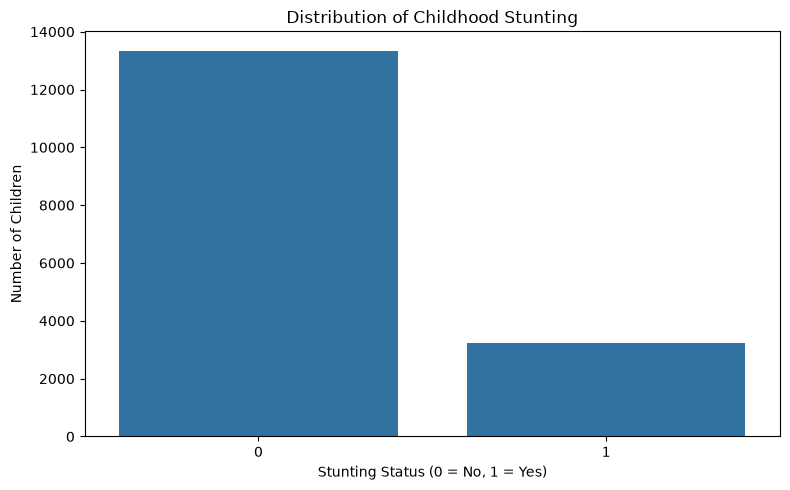

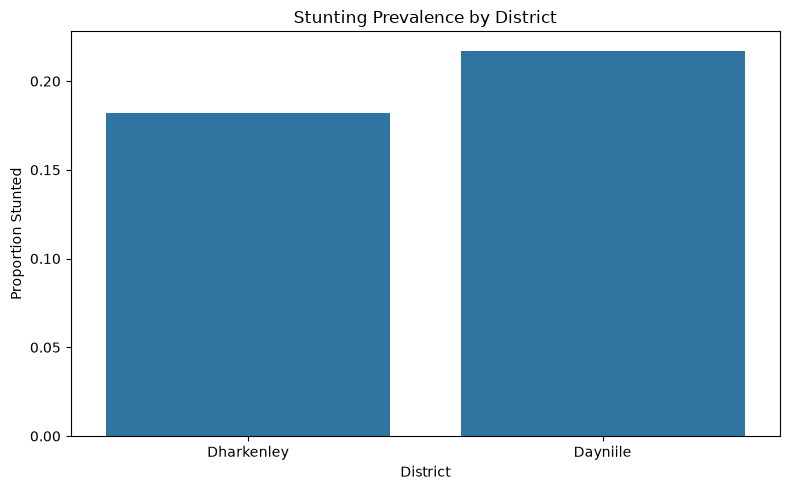


BIVARIATE ANALYSIS

BIVARIATE ASSOCIATION RESULTS


,Variable,Test,Statistic,Degrees_of_Freedom,P_Value
0,MONTHLY_INCOME_CATEGORY_SIM,Pearson Chi-square,468.009396,4.0,5.547884e-100
1,FOOD_INSECURITY_SCORE_SIM,Welch t-test,26.390242,NaN,6.590781e-144
2,FOOD_INSECURITY_SEVERITY_SIM,Pearson Chi-square,582.943864,3.0,5.021631e-126
3,SOCIAL_SUPPORT_SIM,Pearson Chi-square,39.152187,2.0,3.149276e-09
4,HOUSEHOLD_CROWDING_SIM,Pearson Chi-square,43.623469,1.0,3.980369e-11
5,SAFE_DRINKING_WATER_SIM,Pearson Chi-square,226.368217,1.0,3.693183e-51
6,IMPROVED_SANITATION_SIM,Pearson Chi-square,210.315206,1.0,1.172457e-47
7,HEALTH_FACILITY_ACCESS_SIM,Pearson Chi-square,27.393341,2.0,1.126190e-06
8,CAMP_WATER_AVAILABILITY_SIM,Pearson Chi-square,55.878813,2.0,7.346320e-13
9,CAMP_SANITATION_ENVIRONMENT_SIM,Pearson Chi-square,2.198581,2.0,3.331074e-01



MULTICOLLINEARITY ASSESSMENT

VIF RESULTS


,Variable,VIF
0,Intercept,1.000000
1,C(MONTHLY_INCOME_CATEGORY_SIM)[T.Low],1.851884
2,C(MONTHLY_INCOME_CATEGORY_SIM)[T.Lower middle],1.725809
3,C(MONTHLY_INCOME_CATEGORY_SIM)[T.Upper middle],1.599976
4,C(MONTHLY_INCOME_CATEGORY_SIM)[T.Very low],2.881147
5,C(FOOD_INSECURITY_SEVERITY_SIM)[T.Mild],5.458488
6,C(FOOD_INSECURITY_SEVERITY_SIM)[T.Moderate],14.622696
7,C(FOOD_INSECURITY_SEVERITY_SIM)[T.Severe],18.912321
8,C(SOCIAL_SUPPORT_SIM)[T.Low],1.514580
9,C(SOCIAL_SUPPORT_SIM)[T.Moderate],1.531072



Interpretation: VIF values should be examined alongside the model specification. Values above 5 warrant investigation, while values above 10 may indicate substantial multicollinearity.

MULTILEVEL MODEL DATA
Observations: 16584
Households: 3881
Camps: 40

THREE-LEVEL MULTILEVEL LOGISTIC REGRESSION
PYTHON IMPLEMENTATION
Observations: 16584
Number of households: 3881
Number of camps: 40

Checking model data...
Number of observations: 16584
Number of households: 3881
Number of camps: 40

Outcome distribution:
STUNTING_SIM
0    13345
1     3239
Name: count, dtype: int64

Model data checks completed.

FITTING: Empty Three Level Model
Step 1: Constructing model matrices...
Model matrices constructed.
Fixed effect parameters: 1
Random effect parameters: 3921
Variance components: 2

Step 2: Starting Variational Bayes estimation...
|G|=7101.464445
|G|=3741.403966
|G|=5925.584178
|G|=2114.088700
|G|=1994.061034
|G|=1512.146626
|G|=1134.018069
|G|=616.365893
|G|=264.144198
|G|=226.402624
|G|=275

,Variable,Coefficient,Std_Error,Z_Value,P_Value,Odds_Ratio,Lower_CI,Upper_CI,Model
0,Intercept,-2.263084,0.018316,-123.560853,0.000000e+00,0.104029,0.100361,0.107831,Socioeconomic_Model
1,C(MONTHLY_INCOME_CATEGORY_SIM)[T.Low],0.767842,0.052920,14.509613,1.053131e-47,2.155110,1.942779,2.390647,Socioeconomic_Model
2,C(MONTHLY_INCOME_CATEGORY_SIM)[T.Lower middle],0.434539,0.060623,7.167860,7.617894e-13,1.544251,1.371242,1.739087,Socioeconomic_Model
3,C(MONTHLY_INCOME_CATEGORY_SIM)[T.Upper middle],0.223269,0.069398,3.217217,1.294407e-03,1.250156,1.091168,1.432310,Socioeconomic_Model
4,C(MONTHLY_INCOME_CATEGORY_SIM)[T.Very low],0.932281,0.028709,32.473563,2.518944e-231,2.540298,2.401304,2.687337,Socioeconomic_Model
5,C(FOOD_INSECURITY_SEVERITY_SIM)[T.Mild],-0.026272,0.039545,-0.664364,5.064573e-01,0.974070,0.901423,1.052571,Socioeconomic_Model
6,C(FOOD_INSECURITY_SEVERITY_SIM)[T.Moderate],0.024468,0.032192,0.760061,4.472181e-01,1.024770,0.962108,1.091513,Socioeconomic_Model
7,C(FOOD_INSECURITY_SEVERITY_SIM)[T.Severe],-0.087299,0.044297,-1.970770,4.875021e-02,0.916403,0.840195,0.999523,Socioeconomic_Model
8,C(SOCIAL_SUPPORT_SIM)[T.Low],0.027349,0.042220,0.647774,5.171311e-01,1.027726,0.946105,1.116390,Socioeconomic_Model
9,C(SOCIAL_SUPPORT_SIM)[T.Moderate],0.072142,0.029631,2.434657,1.490593e-02,1.074808,1.014164,1.139079,Socioeconomic_Model


... (29 outputs left out)


MODEL CONVERGENCE


,Model,Optimization_Success,Optimization_Message,Singular_Fit
0,Empty_Model,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,Not directly assessed by Variational Bayes
1,Camp_Only_Model,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,Not directly assessed by Variational Bayes
2,Socioeconomic_Model,False,STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT,Not directly assessed by Variational Bayes
3,Health_Model,False,STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT,Not directly assessed by Variational Bayes
4,Comprehensive_Model,False,STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT,Not directly assessed by Variational Bayes



The preferred model should be evaluated using AIC, BIC, log likelihood, convergence and the substantive suitability of its random effects.

MODEL CLASSIFICATION PERFORMANCE


,Metric,Value
0,Accuracy,0.824952
1,Precision,0.723404
2,Recall,0.167953
3,F1 Score,0.272613
4,ROC AUC,0.807909
5,Brier Score,0.124948


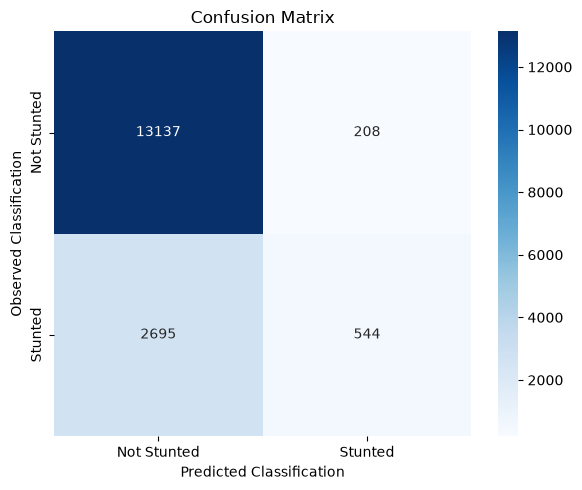

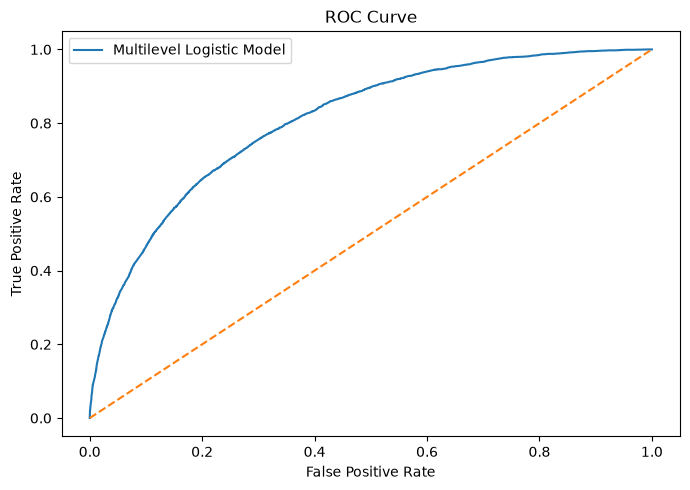

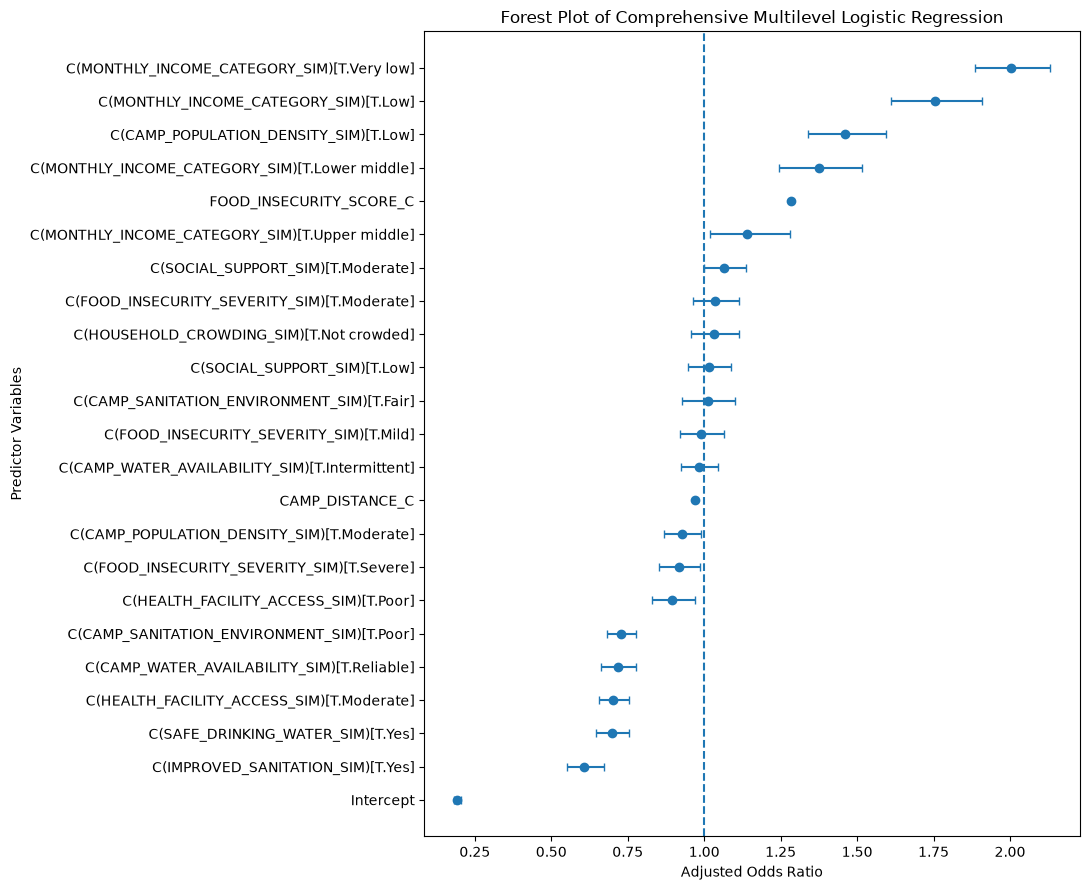

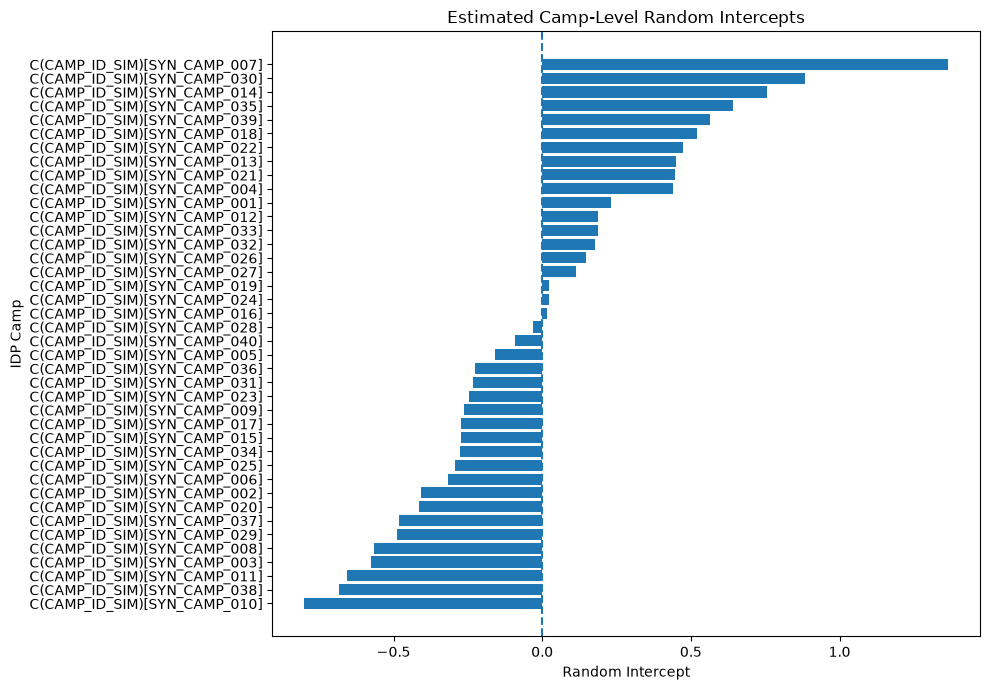


ANALYSIS COMPLETED
Final Excel results: /content/Somalia_Stunting_Multilevel_Analysis_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


All four research objectives have been analysed.
Thank you.


In [1]:
# ================================================================
# MULTILEVEL ANALYSIS OF SOCIOECONOMIC, HEALTH, HOUSEHOLD AND
# COMMUNITY DETERMINANTS OF CHRONIC MALNUTRITION AMONG
# UNDER-FIVE CHILDREN IN MOGADISHU IDP CAMPS, SOMALIA
#
# COMPLETE GOOGLE COLAB ANALYSIS PIPELINE
#
# Research Objectives:
# 1. Household socioeconomic determinants of stunting.
# 2. Health-related determinants of stunting.
# 3. Household and camp-level variance decomposition.
# 4. Identification of significant multilevel predictors.
#
# Main statistical technique:
# Three-level Multilevel Logistic Regression
#
# Estimation:
# Maximum Likelihood using R lme4 through Google Colab.
# ================================================================


# ================================================================
# STEP 1: UPLOAD THE EXCEL DATASET
# ================================================================

from google.colab import files

uploaded = files.upload()

import os
import warnings
import subprocess
import sys

warnings.filterwarnings("ignore")

filename = list(uploaded.keys())[0]

print("Uploaded dataset:", filename)

# ================================================================
# STEP 3: INSTALL PYTHON STATISTICAL PACKAGES
# ================================================================

# Import required libraries

# ================================================================
# FIX GOOGLE COLAB PANDAS IMPORT ERROR
# REINSTALL COMPATIBLE PYTHON STATISTICAL PACKAGES
# ================================================================

import sys
import subprocess

print("Repairing the Python statistical environment...")

# Reinstall a stable pandas version compatible with Python 3.13.
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--no-cache-dir",
    "--force-reinstall",
    "pandas==2.3.3"
])

print("\nPandas installation completed.")
print("IMPORTANT: Restart the Google Colab runtime before proceeding.")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import expit
from scipy.stats import chi2_contingency, ttest_ind, norm

from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

from statsmodels.stats.outliers_influence import variance_inflation_factor

from patsy import dmatrix

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    brier_score_loss
)

import warnings

warnings.filterwarnings("ignore")

np.random.seed(123)

print("Python statistical environment is ready.")

# ================================================================
# STEP 4: IMPORT THE DATASET
# ================================================================

df = pd.read_excel(filename)

print("\nDATASET INFORMATION")

print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

print("\nVariable names:")

print(df.columns.tolist())

print("\nFirst five observations:")

display(df.head())

print("\nDataset information:")

df.info()


# ================================================================
# STEP 5: VERIFY REQUIRED VARIABLES
# ================================================================

required_variables = [

    "ROW_ID",

    "CHILD_ID_SIM",

    "HOUSEHOLD_ID_SIM",

    "CAMP_ID_SIM",

    "DISTRICT_SIM",

    "IDP_STATUS_SIM",

    "MONTHLY_INCOME_CATEGORY_SIM",

    "FOOD_INSECURITY_SCORE_SIM",

    "FOOD_INSECURITY_SEVERITY_SIM",

    "SOCIAL_SUPPORT_SIM",

    "SAFE_DRINKING_WATER_SIM",

    "IMPROVED_SANITATION_SIM",

    "HOUSEHOLD_CROWDING_SIM",

    "CAMP_POPULATION_DENSITY_SIM",

    "HEALTH_FACILITY_ACCESS_SIM",

    "CAMP_WATER_AVAILABILITY_SIM",

    "CAMP_SANITATION_ENVIRONMENT_SIM",

    "CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM",

    "HAZ_SIM",

    "STUNTING_SIM",

    "STUNTING_STATUS_SIM"
]

missing_columns = [

    x for x in required_variables

    if x not in df.columns

]

if missing_columns:

    raise ValueError(
        f"Required variables missing: {missing_columns}"
    )

print("\nAll required dataset variables are available.")


# ================================================================
# STEP 6: DATA PREPROCESSING AND CLEANING
# ================================================================

print("\nDATA PREPROCESSING")

# Remove completely duplicated rows.

initial_n = len(df)

df = df.drop_duplicates()

print(
    "Completely duplicated records removed:",
    initial_n - len(df)
)

# Check unique observation identifier.

if df["ROW_ID"].duplicated().any():

    raise ValueError(
        "ROW_ID contains duplicates. Resolve observation "
        "identification before proceeding."
    )

# Check missing observations.

missing_summary = pd.DataFrame({

    "Missing_Count": df.isnull().sum(),

    "Missing_Percentage":
        df.isnull().mean() * 100

})

print("\nMissing observations:")

display(missing_summary)

# Convert numeric variables.

numeric_variables = [

    "FOOD_INSECURITY_SCORE_SIM",

    "CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM",

    "HAZ_SIM",

    "STUNTING_SIM"

]

for col in numeric_variables:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Remove observations without valid outcome or hierarchy IDs.

df = df.dropna(

    subset=[

        "STUNTING_SIM",

        "HAZ_SIM",

        "HOUSEHOLD_ID_SIM",

        "CAMP_ID_SIM"

    ]

).copy()

# Ensure the outcome is binary.

df = df[
    df["STUNTING_SIM"].isin([0, 1])
].copy()

# Validate the stunting definition.

df["STUNTING_FROM_HAZ"] = (

    df["HAZ_SIM"] < -2

).astype(int)

mismatch = (

    df["STUNTING_SIM"] !=
    df["STUNTING_FROM_HAZ"]

).sum()

print(
    "\nDisagreement between STUNTING_SIM and HAZ:",
    mismatch
)

if mismatch > 0:

    raise ValueError(
        "Stunting classification disagrees with HAZ. "
        "Resolve the discrepancy before analysis."
    )

# Check under-five population eligibility.

print(
    "\nWARNING: The dataset does not contain child age. "
    "Therefore, the 0 to 59 month eligibility criterion "
    "cannot be independently verified."
)

# Check IDP status.

print("\nIDP status distribution:")

display(
    df["IDP_STATUS_SIM"].value_counts()
)

# Create a unique household identifier nested within camp.

df["HOUSEHOLD_UID"] = (

    df["CAMP_ID_SIM"].astype(str)

    + "_"

    + df["HOUSEHOLD_ID_SIM"].astype(str)

)

# Convert categorical variables to string.

categorical_variables = [

    "DISTRICT_SIM",

    "MONTHLY_INCOME_CATEGORY_SIM",

    "FOOD_INSECURITY_SEVERITY_SIM",

    "SOCIAL_SUPPORT_SIM",

    "SAFE_DRINKING_WATER_SIM",

    "IMPROVED_SANITATION_SIM",

    "HOUSEHOLD_CROWDING_SIM",

    "CAMP_POPULATION_DENSITY_SIM",

    "HEALTH_FACILITY_ACCESS_SIM",

    "CAMP_WATER_AVAILABILITY_SIM",

    "CAMP_SANITATION_ENVIRONMENT_SIM"

]

for col in categorical_variables:

    df[col] = (

        df[col]

        .astype("string")

        .str.strip()

    )

    df[col] = df[col].replace(

        ["", "NA", "N/A", "nan", "None"],

        pd.NA

    )

print("\nPreprocessing completed.")

print("Final sample size:", len(df))

print(
    "Unique households:",
    df["HOUSEHOLD_UID"].nunique()
)

print(
    "Unique IDP camps:",
    df["CAMP_ID_SIM"].nunique()
)


# ================================================================
# STEP 7: DEFINE ANALYTICAL VARIABLE GROUPS
# ================================================================

# Outcome variable.

outcome = "STUNTING_SIM"


# SOCIOECONOMIC AND HOUSEHOLD VARIABLES.

socioeconomic_variables = [

    "MONTHLY_INCOME_CATEGORY_SIM",

    "FOOD_INSECURITY_SCORE_SIM",

    "FOOD_INSECURITY_SEVERITY_SIM",

    "SOCIAL_SUPPORT_SIM",

    "HOUSEHOLD_CROWDING_SIM"

]


# HEALTH-RELATED AND ENVIRONMENTAL ACCESS VARIABLES.

health_variables = [

    "SAFE_DRINKING_WATER_SIM",

    "IMPROVED_SANITATION_SIM",

    "HEALTH_FACILITY_ACCESS_SIM",

    "CAMP_WATER_AVAILABILITY_SIM",

    "CAMP_SANITATION_ENVIRONMENT_SIM",

    "CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM"

]


# COMMUNITY VARIABLES.

community_variables = [

    "CAMP_POPULATION_DENSITY_SIM",

    "CAMP_WATER_AVAILABILITY_SIM",

    "CAMP_SANITATION_ENVIRONMENT_SIM",

    "HEALTH_FACILITY_ACCESS_SIM",

    "CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM"

]


# COMPREHENSIVE PREDICTOR VARIABLES.

all_predictors = list(dict.fromkeys(

    socioeconomic_variables +

    health_variables +

    community_variables

))


# ================================================================
# STEP 8: DESCRIPTIVE STATISTICAL ANALYSIS
# ================================================================

print("\n================================================")
print("DESCRIPTIVE STATISTICAL ANALYSIS")
print("================================================")

# Overall stunting prevalence.

stunting_frequency = (

    df[outcome]

    .value_counts()

    .sort_index()

)

stunting_percentage = (

    df[outcome]

    .value_counts(normalize=True)

    .sort_index() * 100

)

stunting_summary = pd.DataFrame({

    "Stunting_Status": [

        "Not Stunted",

        "Stunted"

    ],

    "Frequency": [

        stunting_frequency.get(0, 0),

        stunting_frequency.get(1, 0)

    ],

    "Percentage": [

        stunting_percentage.get(0, 0),

        stunting_percentage.get(1, 0)

    ]

})

print("\nSTUNTING PREVALENCE")

display(stunting_summary)

# Continuous variable summary.

continuous_summary = (

    df[

        [

            "HAZ_SIM",

            "FOOD_INSECURITY_SCORE_SIM",

            "CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM"

        ]

    ]

    .describe()

    .T

)

print("\nCONTINUOUS VARIABLE SUMMARY")

display(continuous_summary)

# Categorical variable frequencies.

categorical_tables = {}

for col in categorical_variables:

    tab = pd.DataFrame({

        "Frequency": df[col].value_counts(dropna=False),

        "Percentage":

            df[col].value_counts(
                normalize=True,
                dropna=False
            ) * 100

    })

    categorical_tables[col] = tab

    print("\n", col)

    display(tab)


# ================================================================
# STEP 9: VISUALIZATION OF STUNTING PREVALENCE
# ================================================================

plt.figure(figsize=(8, 5))

sns.countplot(

    data=df,

    x=outcome

)

plt.title("Distribution of Childhood Stunting")

plt.xlabel("Stunting Status (0 = No, 1 = Yes)")

plt.ylabel("Number of Children")

plt.tight_layout()

plt.show()


# Stunting distribution by district.

plt.figure(figsize=(8, 5))

sns.barplot(

    data=df,

    x="DISTRICT_SIM",

    y=outcome,

    errorbar=None

)

plt.title("Stunting Prevalence by District")

plt.ylabel("Proportion Stunted")

plt.xlabel("District")

plt.tight_layout()

plt.show()


# ================================================================
# STEP 10: BIVARIATE ANALYSIS
# ================================================================

print("\n================================================")
print("BIVARIATE ANALYSIS")
print("================================================")

bivariate_results = []

for col in all_predictors:

    temp = df[[col, outcome]].dropna()

    if temp[col].nunique() < 2:

        continue

    if pd.api.types.is_numeric_dtype(temp[col]):

        group1 = temp.loc[
            temp[outcome] == 1, col
        ]

        group0 = temp.loc[
            temp[outcome] == 0, col
        ]

        if len(group1) > 1 and len(group0) > 1:

            stat, pvalue = ttest_ind(

                group1,

                group0,

                equal_var=False

            )

            test_name = "Welch t-test"

        else:

            continue

        bivariate_results.append({

            "Variable": col,

            "Test": test_name,

            "Statistic": stat,

            "P_Value": pvalue

        })

    else:

        table = pd.crosstab(

            temp[col],

            temp[outcome]

        )

        if table.shape[0] < 2 or table.shape[1] < 2:

            continue

        chi2, pvalue, dof, expected = (

            chi2_contingency(table)

        )

        bivariate_results.append({

            "Variable": col,

            "Test": "Pearson Chi-square",

            "Statistic": chi2,

            "Degrees_of_Freedom": dof,

            "P_Value": pvalue

        })


bivariate_results = pd.DataFrame(

    bivariate_results

)

print("\nBIVARIATE ASSOCIATION RESULTS")

display(bivariate_results)


# ================================================================
# STEP 11: MULTICOLLINEARITY ASSESSMENT
# ================================================================

print("\n================================================")
print("MULTICOLLINEARITY ASSESSMENT")
print("================================================")

vif_formula = """

1 +

C(MONTHLY_INCOME_CATEGORY_SIM) +

FOOD_INSECURITY_SCORE_SIM +

C(FOOD_INSECURITY_SEVERITY_SIM) +

C(SOCIAL_SUPPORT_SIM) +

C(HOUSEHOLD_CROWDING_SIM) +

C(SAFE_DRINKING_WATER_SIM) +

C(IMPROVED_SANITATION_SIM) +

C(HEALTH_FACILITY_ACCESS_SIM) +

C(CAMP_POPULATION_DENSITY_SIM) +

C(CAMP_WATER_AVAILABILITY_SIM) +

C(CAMP_SANITATION_ENVIRONMENT_SIM) +

C(DISTRICT_SIM) +

CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM

"""

vif_data = df.dropna(

    subset=all_predictors + ["DISTRICT_SIM"]

).copy()

X_vif = dmatrix(

    vif_formula,

    data=vif_data,

    return_type="dataframe"

)

vif_results = pd.DataFrame({

    "Variable": X_vif.columns,

    "VIF": [

        variance_inflation_factor(

            X_vif.values,

            i

        )

        for i in range(X_vif.shape[1])

    ]

})

print("\nVIF RESULTS")

display(vif_results)

print(
    "\nInterpretation: VIF values should be examined "
    "alongside the model specification. Values above "
    "5 warrant investigation, while values above 10 "
    "may indicate substantial multicollinearity."
)


# ================================================================
# STEP 12: PREPARE DATA FOR MULTILEVEL LOGISTIC REGRESSION
# ================================================================

model_variables = list(dict.fromkeys(

    [

        outcome,

        "CAMP_ID_SIM",

        "HOUSEHOLD_UID"

    ] + all_predictors

))

model_df = df[model_variables].dropna().copy()

# Ensure categorical variables are factors in R.

model_df.to_csv(

    "/content/multilevel_analysis_data.csv",

    index=False

)

print("\nMULTILEVEL MODEL DATA")

print("Observations:", len(model_df))

print(

    "Households:",

    model_df["HOUSEHOLD_UID"].nunique()

)

print(

    "Camps:",

    model_df["CAMP_ID_SIM"].nunique()

)

# ================================================================
# STEP 13: THREE-LEVEL BAYESIAN MULTILEVEL LOGISTIC REGRESSION
# PYTHON IMPLEMENTATION
#
# Estimation: Variational Bayes
#
# Level 1: Children
# Level 2: Households
# Level 3: IDP Camps
# ================================================================

print("\n================================================")
print("THREE-LEVEL MULTILEVEL LOGISTIC REGRESSION")
print("PYTHON IMPLEMENTATION")
print("================================================")


# ------------------------------------------------
# 13.1 PREPARE THE MODEL DATA
# ------------------------------------------------

model_df = df[

    list(dict.fromkeys(

        [

            "STUNTING_SIM",

            "CAMP_ID_SIM",

            "HOUSEHOLD_UID"

        ] + all_predictors

    ))

].dropna().copy()


model_df["STUNTING_SIM"] = (

    model_df["STUNTING_SIM"].astype(int)

)

# Ensure correct categorical representation.

categorical_model_variables = [

    "MONTHLY_INCOME_CATEGORY_SIM",

    "FOOD_INSECURITY_SEVERITY_SIM",

    "SOCIAL_SUPPORT_SIM",

    "HOUSEHOLD_CROWDING_SIM",

    "SAFE_DRINKING_WATER_SIM",

    "IMPROVED_SANITATION_SIM",

    "HEALTH_FACILITY_ACCESS_SIM",

    "CAMP_POPULATION_DENSITY_SIM",

    "CAMP_WATER_AVAILABILITY_SIM",

    "CAMP_SANITATION_ENVIRONMENT_SIM"

]

for col in categorical_model_variables:

    model_df[col] = model_df[col].astype("category")


model_df["CAMP_ID_SIM"] = (

    model_df["CAMP_ID_SIM"].astype("category")

)

model_df["HOUSEHOLD_UID"] = (

    model_df["HOUSEHOLD_UID"].astype("category")

)


# Centre continuous predictors.

model_df["FOOD_INSECURITY_SCORE_C"] = (

    model_df["FOOD_INSECURITY_SCORE_SIM"]

    - model_df["FOOD_INSECURITY_SCORE_SIM"].mean()

)


model_df["CAMP_DISTANCE_C"] = (

    model_df["CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM"]

    - model_df[
        "CAMP_DISTANCE_TO_HEALTH_FACILITY_KM_SIM"
    ].mean()

)


print("Observations:", len(model_df))

print(

    "Number of households:",

    model_df["HOUSEHOLD_UID"].nunique()

)

print(

    "Number of camps:",

    model_df["CAMP_ID_SIM"].nunique()

)


# ------------------------------------------------
# 13.2 DEFINE THE RANDOM EFFECTS
# ------------------------------------------------

# Camp random intercepts.

# Household random intercepts.

random_effects_both = {

    "camp": "0 + C(CAMP_ID_SIM)",

    "household": "0 + C(HOUSEHOLD_UID)"

}


random_effects_camp = {

    "camp": "0 + C(CAMP_ID_SIM)"

}


# ================================================================
# REVISED MODEL ESTIMATION FUNCTION
# THREE LEVEL BAYESIAN MULTILEVEL LOGISTIC REGRESSION
#
# Level 1: Children
# Level 2: Households
# Level 3: IDP Camps
#
# Estimation: Variational Bayes
# Optimisation: L-BFGS-B
# ================================================================

import time
import gc
import numpy as np
import pandas as pd

from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM


# ------------------------------------------------
# 13.3 CHECK MODEL DATA BEFORE ESTIMATION
# ------------------------------------------------

print("\nChecking model data...")

print("Number of observations:", len(model_df))
print("Number of households:", model_df["HOUSEHOLD_UID"].nunique())
print("Number of camps:", model_df["CAMP_ID_SIM"].nunique())

print("\nOutcome distribution:")

print(model_df["STUNTING_SIM"].value_counts())

if model_df["STUNTING_SIM"].nunique() != 2:
    raise ValueError(
        "The dependent variable must contain both 0 and 1."
    )

if model_df.isnull().sum().sum() > 0:
    raise ValueError(
        "Missing values remain in the model dataset."
    )

print("\nModel data checks completed.")


# ------------------------------------------------
# 13.4 DEFINE RANDOM EFFECTS
# ------------------------------------------------

random_effects_both = {

    "camp": "0 + C(CAMP_ID_SIM)",

    "household": "0 + C(HOUSEHOLD_UID)"

}

random_effects_camp = {

    "camp": "0 + C(CAMP_ID_SIM)"

}


# ------------------------------------------------
# 13.5 REVISED MODEL FITTING FUNCTION
# ------------------------------------------------

def fit_multilevel_model(

    formula,

    random_effects,

    model_name

):

    print("\n" + "=" * 60)

    print("FITTING:", model_name)

    print("=" * 60)

    start_time = time.time()

    try:

        # Construct the model.

        print("Step 1: Constructing model matrices...")

        model = BinomialBayesMixedGLM.from_formula(

            formula,

            random_effects,

            model_df

        )

        print("Model matrices constructed.")

        print(
            "Fixed effect parameters:",
            model.exog.shape[1]
        )

        print(
            "Random effect parameters:",
            model.exog_vc.shape[1]
        )

        print(
            "Variance components:",
            len(model.vcp_names)
        )

        # Estimate the model using a memory-efficient
        # quasi-Newton optimisation method.

        print("\nStep 2: Starting Variational Bayes estimation...")

        result = model.fit_vb(

            fit_method="L-BFGS-B",

            minim_opts={

                "maxiter": 300,

                "ftol": 1e-6,

                "gtol": 1e-4,

                "maxls": 30

            },

            verbose=True

        )

        elapsed_time = time.time() - start_time

        print("\nStep 3: Estimation finished.")

        print("Model:", model_name)

        print(
            "Time taken:",
            round(elapsed_time, 2),
            "seconds"
        )

        # Check optimisation status.

        optimisation = getattr(
            result,
            "optim_retvals",
            None
        )

        if optimisation is not None:

            print(
                "Optimisation successful:",
                getattr(optimisation, "success", None)
            )

            print(
                "Optimisation message:",
                getattr(optimisation, "message", None)
            )

            print(
                "Final optimisation objective:",
                getattr(optimisation, "fun", None)
            )

        # Release temporary objects.

        gc.collect()

        return model, result

    except Exception as error:

        print("\nMODEL ESTIMATION FAILED")

        print("Model:", model_name)

        print("Error type:", type(error).__name__)

        print("Error message:", str(error))

        raise


# ------------------------------------------------
# 13.6 MODEL 0: EMPTY THREE LEVEL MODEL
# ------------------------------------------------

formula_empty = "STUNTING_SIM ~ 1"

model0, result0 = fit_multilevel_model(

    formula_empty,

    random_effects_both,

    "Empty Three Level Model"

)


# ------------------------------------------------
# 13.7 MODEL 1: CAMP RANDOM INTERCEPT MODEL
# ------------------------------------------------

model1, result1 = fit_multilevel_model(

    formula_empty,

    random_effects_camp,

    "Camp Random Intercept Model"

)


# ------------------------------------------------
# 13.8 MODEL 2: SOCIOECONOMIC MODEL
# OBJECTIVE ONE
# ------------------------------------------------

formula_socio = """

STUNTING_SIM ~

C(MONTHLY_INCOME_CATEGORY_SIM) +

FOOD_INSECURITY_SCORE_C +

C(FOOD_INSECURITY_SEVERITY_SIM) +

C(SOCIAL_SUPPORT_SIM) +

C(HOUSEHOLD_CROWDING_SIM)

"""

model_socio, result_socio = fit_multilevel_model(

    formula_socio,

    random_effects_both,

    "Socioeconomic Model"

)


# ------------------------------------------------
# 13.9 MODEL 3: HEALTH AND ENVIRONMENTAL MODEL
# OBJECTIVE TWO
# ------------------------------------------------

formula_health = """

STUNTING_SIM ~

C(SAFE_DRINKING_WATER_SIM) +

C(IMPROVED_SANITATION_SIM) +

C(HEALTH_FACILITY_ACCESS_SIM) +

C(CAMP_WATER_AVAILABILITY_SIM) +

C(CAMP_SANITATION_ENVIRONMENT_SIM) +

CAMP_DISTANCE_C

"""

model_health, result_health = fit_multilevel_model(

    formula_health,

    random_effects_both,

    "Health and Environmental Model"

)


# ------------------------------------------------
# 13.10 MODEL 4: COMPREHENSIVE THREE LEVEL MODEL
# OBJECTIVE FOUR
# ------------------------------------------------

formula_full = """

STUNTING_SIM ~

C(MONTHLY_INCOME_CATEGORY_SIM) +

FOOD_INSECURITY_SCORE_C +

C(FOOD_INSECURITY_SEVERITY_SIM) +

C(SOCIAL_SUPPORT_SIM) +

C(HOUSEHOLD_CROWDING_SIM) +

C(SAFE_DRINKING_WATER_SIM) +

C(IMPROVED_SANITATION_SIM) +

C(HEALTH_FACILITY_ACCESS_SIM) +

C(CAMP_POPULATION_DENSITY_SIM) +

C(CAMP_WATER_AVAILABILITY_SIM) +

C(CAMP_SANITATION_ENVIRONMENT_SIM) +

CAMP_DISTANCE_C

"""

model_full, result_full = fit_multilevel_model(

    formula_full,

    random_effects_both,

    "Comprehensive Three Level Model"

)


# ------------------------------------------------
# 13.11 STORE ALL ESTIMATED MODELS
# ------------------------------------------------

models = {

    "Empty_Model": (model0, result0),

    "Camp_Only_Model": (model1, result1),

    "Socioeconomic_Model": (
        model_socio,
        result_socio
    ),

    "Health_Model": (
        model_health,
        result_health
    ),

    "Comprehensive_Model": (
        model_full,
        result_full
    )

}

print("\n" + "=" * 60)

print("ALL FIVE MULTILEVEL MODELS HAVE BEEN ESTIMATED")

print("=" * 60)


# ------------------------------------------------
# 13.9 STORE ALL MODELS
# ------------------------------------------------

models = {

    "Empty_Model": (model0, result0),

    "Camp_Only_Model": (model1, result1),

    "Socioeconomic_Model": (

        model_socio,

        result_socio

    ),

    "Health_Model": (

        model_health,

        result_health

    ),

    "Comprehensive_Model": (

        model_full,

        result_full

    )

}


# ------------------------------------------------
# 13.10 EXTRACT FIXED EFFECTS
# ------------------------------------------------

def extract_fixed_effects(

    model,

    result,

    model_name

):

    coefficients = np.asarray(result.fe_mean)

    standard_errors = np.asarray(result.fe_sd)

    variable_names = model.exog_names

    z_values = coefficients / standard_errors

    p_values = 2 * norm.sf(np.abs(z_values))

    lower = coefficients - 1.96 * standard_errors

    upper = coefficients + 1.96 * standard_errors

    output = pd.DataFrame({

        "Variable": variable_names,

        "Coefficient": coefficients,

        "Std_Error": standard_errors,

        "Z_Value": z_values,

        "P_Value": p_values,

        "Odds_Ratio": np.exp(coefficients),

        "Lower_CI": np.exp(lower),

        "Upper_CI": np.exp(upper),

        "Model": model_name

    })

    return output


fixed_effects = pd.concat(

    [

        extract_fixed_effects(

            model,

            result,

            name

        )

        for name, (model, result) in models.items()

        if name in [

            "Socioeconomic_Model",

            "Health_Model",

            "Comprehensive_Model"

        ]

    ],

    ignore_index=True

)


fixed_effects.to_csv(

    "/content/fixed_effects_results.csv",

    index=False

)


# ------------------------------------------------
# 13.11 EXTRACT RANDOM EFFECT VARIANCES
# ------------------------------------------------

def extract_variances(model, result):

    names = list(model.vcp_names)

    means = np.asarray(result.vcp_mean)

    sds = np.asarray(result.vcp_sd)

    # Posterior median of each random-effect variance.

    variances = np.exp(2 * means)

    return {

        name: variance

        for name, variance in zip(names, variances)

    }


empty_variances = extract_variances(

    model0,

    result0

)


full_variances = extract_variances(

    model_full,

    result_full

)


print("\nEMPTY MODEL VARIANCES")

print(empty_variances)

print("\nCOMPREHENSIVE MODEL VARIANCES")

print(full_variances)


# ------------------------------------------------
# 13.12 OBJECTIVE THREE: VARIANCE DECOMPOSITION
# ------------------------------------------------

camp_variance = empty_variances["camp"]

household_variance = empty_variances["household"]

individual_variance = np.pi**2 / 3

total_variance = (

    camp_variance +

    household_variance +

    individual_variance

)


icc_results = pd.DataFrame({

    "Measure": [

        "Camp ICC",

        "Household Conditional ICC",

        "Same Household Total ICC"

    ],

    "Estimate": [

        camp_variance / total_variance,

        household_variance / total_variance,

        (

            camp_variance +

            household_variance

        ) / total_variance

    ]

})


icc_results["Percentage"] = (

    icc_results["Estimate"] * 100

)


variance_components = pd.DataFrame({

    "Variance_Component": [

        "Camp_Level_Variance",

        "Household_Level_Variance",

        "Individual_Level_Logistic_Variance",

        "Total_Variance"

    ],

    "Estimate": [

        camp_variance,

        household_variance,

        individual_variance,

        total_variance

    ]

})


icc_results.to_csv(

    "/content/ICC_results.csv",

    index=False

)


variance_components.to_csv(

    "/content/variance_components.csv",

    index=False

)


# ------------------------------------------------
# 13.13 VARIANCE REDUCTION
# ------------------------------------------------

variance_reduction = pd.DataFrame({

    "Level": [

        "Camp",

        "Household"

    ],

    "Empty_Model_Variance": [

        empty_variances["camp"],

        empty_variances["household"]

    ],

    "Full_Model_Variance": [

        full_variances["camp"],

        full_variances["household"]

    ]

})


variance_reduction[

    "Percentage_Variance_Reduction"

] = (

    100 *

    (

        variance_reduction["Empty_Model_Variance"] -

        variance_reduction["Full_Model_Variance"]

    ) /

    variance_reduction["Empty_Model_Variance"]

)


variance_reduction.to_csv(

    "/content/variance_reduction.csv",

    index=False

)


# ------------------------------------------------
# 13.14 MODEL COMPARISON USING ELBO
# ------------------------------------------------

fit_results = []

for name, (model, result) in models.items():

    retvals = getattr(result, "optim_retvals", None)

    if retvals is not None:

        elbo = -retvals.fun

        success = getattr(

            retvals,

            "success",

            None

        )

        message = getattr(

            retvals,

            "message",

            ""

        )

    else:

        elbo = np.nan

        success = None

        message = "Optimization information unavailable"

    fit_results.append({

        "Model": name,

        "Observations": len(model_df),

        "ELBO": elbo,

        "Optimization_Success": success,

        "Optimization_Message": str(message)

    })


fit_comparison = pd.DataFrame(fit_results)


fit_comparison.to_csv(

    "/content/model_fit_comparison.csv",

    index=False

)


# ------------------------------------------------
# 13.15 MODEL CONVERGENCE INFORMATION
# ------------------------------------------------

convergence_results = fit_comparison[

    [

        "Model",

        "Optimization_Success",

        "Optimization_Message"

    ]

].copy()


convergence_results["Singular_Fit"] = (

    "Not directly assessed by Variational Bayes"

)


convergence_results.to_csv(

    "/content/model_convergence.csv",

    index=False

)


# ------------------------------------------------
# 13.16 RANDOM EFFECT ESTIMATES
# ------------------------------------------------

def extract_random_effects(model, result, prefix):

    values = np.asarray(result.vc_mean)

    names = list(model.vc_names)

    output = pd.DataFrame({

        "ID": names,

        "Random_Intercept": values

    })

    output = output[

        output["ID"].str.contains(

            prefix,

            case=False,

            regex=False

        )

    ].copy()

    return output


camp_random_effects = extract_random_effects(

    model_full,

    result_full,

    "CAMP_ID_SIM"

)


household_random_effects = extract_random_effects(

    model_full,

    result_full,

    "HOUSEHOLD_UID"

)


camp_random_effects.to_csv(

    "/content/camp_random_effects.csv",

    index=False

)


household_random_effects.to_csv(

    "/content/household_random_effects.csv",

    index=False

)


# ------------------------------------------------
# 13.17 PREDICTED PROBABILITIES
# ------------------------------------------------

# Fixed effects component.

fixed_predictor = (

    np.asarray(model_full.exog) @

    np.asarray(result_full.fe_mean)

)


# Random effects component.

random_predictor = (

    np.asarray(

        model_full.exog_vc @

        np.asarray(result_full.vc_mean)

    ).ravel()

)


# Combined linear predictor.

linear_predictor = (

    fixed_predictor +

    random_predictor

)


predicted_probability = expit(

    linear_predictor

)


prediction_results = pd.DataFrame({

    "Observed": model_df["STUNTING_SIM"].values,

    "Predicted_Probability": predicted_probability,

    "Predicted_Class": (

        predicted_probability >= 0.5

    ).astype(int)

})


prediction_results.to_csv(

    "/content/model_predictions.csv",

    index=False

)


# ------------------------------------------------
# 13.18 SAVE RESULTS
# ------------------------------------------------

objective_one = fixed_effects[

    fixed_effects["Model"] == "Socioeconomic_Model"

].copy()


objective_two = fixed_effects[

    fixed_effects["Model"] == "Health_Model"

].copy()


objective_four = fixed_effects[

    fixed_effects["Model"] == "Comprehensive_Model"

].copy()


significant_predictors = objective_four[

    objective_four["P_Value"] < 0.05

].copy()


print("\n================================================")

print("PYTHON MULTILEVEL MODELLING COMPLETED")

print("================================================")

print("\nOBJECTIVE ONE")

display(objective_one)


print("\nOBJECTIVE TWO")

display(objective_two)


print("\nOBJECTIVE THREE")

display(variance_components)

display(icc_results)


print("\nOBJECTIVE FOUR")

display(objective_four)


print("\nSIGNIFICANT PREDICTORS")

display(significant_predictors)


print("\nMODEL COMPARISON")

display(fit_comparison)


print("\nMODEL CONVERGENCE")

display(convergence_results)


print("\nAll modelling results exported successfully.")

# ================================================================
# STEP 14: IMPORT MULTILEVEL REGRESSION RESULTS
# ================================================================

fixed_effects = pd.read_csv(

    "/content/fixed_effects_results.csv"

)

fit_comparison = pd.read_csv(

    "/content/model_fit_comparison.csv"

)

variance_components = pd.read_csv(

    "/content/variance_components.csv"

)

icc_results = pd.read_csv(

    "/content/ICC_results.csv"

)

variance_reduction = pd.read_csv(

    "/content/variance_reduction.csv"

)

convergence_results = pd.read_csv(

    "/content/model_convergence.csv"

)

predictions = pd.read_csv(

    "/content/model_predictions.csv"

)

camp_random_effects = pd.read_csv(

    "/content/camp_random_effects.csv"

)

household_random_effects = pd.read_csv(

    "/content/household_random_effects.csv"

)


# ================================================================
# STEP 15: PRESENT OBJECTIVE ONE RESULTS
# SOCIOECONOMIC DETERMINANTS
# ================================================================

print("\n================================================")
print("OBJECTIVE ONE: SOCIOECONOMIC DETERMINANTS")
print("================================================")

objective_one = fixed_effects[
    fixed_effects["Model"] == "Socioeconomic_Model"
].copy()

display(

    objective_one[

        [

            "Variable",

            "Coefficient",

            "Odds_Ratio",

            "Lower_CI",

            "Upper_CI",

            "P_Value"

        ]

    ]

)

print(

    "\nInterpretation: Odds ratios above one indicate "
    "higher adjusted odds of stunting, whereas odds "
    "ratios below one indicate lower adjusted odds, "
    "relative to the relevant reference category."
)


# ================================================================
# STEP 16: PRESENT OBJECTIVE TWO RESULTS
# HEALTH-RELATED DETERMINANTS
# ================================================================

print("\n================================================")
print("OBJECTIVE TWO: HEALTH-RELATED DETERMINANTS")
print("================================================")

objective_two = fixed_effects[
    fixed_effects["Model"] == "Health_Model"
].copy()

display(

    objective_two[

        [

            "Variable",

            "Coefficient",

            "Odds_Ratio",

            "Lower_CI",

            "Upper_CI",

            "P_Value"

        ]

    ]

)


# ================================================================
# STEP 17: PRESENT OBJECTIVE THREE RESULTS
# VARIANCE DECOMPOSITION AND ICC
# ================================================================

print("\n================================================")
print("OBJECTIVE THREE: VARIANCE DECOMPOSITION")
print("================================================")

print("\nRandom Effects Variance Components")

display(variance_components)

print("\nIntraclass Correlation Coefficients")

display(icc_results)

print("\nVariance Reduction")

display(variance_reduction)

print(

    "\nInterpretation: Camp ICC represents the "
    "proportion of latent outcome variance attributable "
    "to differences between camps. Household conditional "
    "ICC represents the household contribution after "
    "accounting for camp clustering. The same-household "
    "ICC represents the combined household and camp "
    "contribution to clustering."
)


# ================================================================
# STEP 18: PRESENT OBJECTIVE FOUR RESULTS
# COMPREHENSIVE MULTILEVEL LOGISTIC REGRESSION
# ================================================================

print("\n================================================")
print("OBJECTIVE FOUR: COMPREHENSIVE MULTILEVEL MODEL")
print("================================================")

objective_four = fixed_effects[
    fixed_effects["Model"] == "Comprehensive_Model"
].copy()

display(

    objective_four[

        [

            "Variable",

            "Coefficient",

            "Std_Error",

            "Odds_Ratio",

            "Lower_CI",

            "Upper_CI",

            "P_Value"

        ]

    ]

)

# Identify statistically significant predictors.

significant_predictors = objective_four[

    objective_four["P_Value"] < 0.05

].copy()

print("\nSTATISTICALLY SIGNIFICANT PREDICTORS")

display(significant_predictors)


# ================================================================
# STEP 19: MODEL FIT COMPARISON
# ================================================================

print("\n================================================")
print("MODEL FIT AND COMPARISON")
print("================================================")

display(fit_comparison)

print("\nMODEL CONVERGENCE")

display(convergence_results)

print(

    "\nThe preferred model should be evaluated using "
    "AIC, BIC, log likelihood, convergence and the "
    "substantive suitability of its random effects."
)


# ================================================================
# STEP 20: MODEL CLASSIFICATION PERFORMANCE
# ================================================================

print("\n================================================")
print("MODEL CLASSIFICATION PERFORMANCE")
print("================================================")

y_true = predictions["Observed"]

y_prob = predictions["Predicted_Probability"]

y_pred = predictions["Predicted_Class"]

classification_results = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1 Score",

        "ROC AUC",

        "Brier Score"

    ],

    "Value": [

        accuracy_score(y_true, y_pred),

        precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        roc_auc_score(y_true, y_prob),

        brier_score_loss(y_true, y_prob)

    ]

})

display(classification_results)


# Confusion matrix.

cm = confusion_matrix(

    y_true,

    y_pred

)

plt.figure(figsize=(6, 5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=["Not Stunted", "Stunted"],

    yticklabels=["Not Stunted", "Stunted"]

)

plt.title("Confusion Matrix")

plt.xlabel("Predicted Classification")

plt.ylabel("Observed Classification")

plt.tight_layout()

plt.show()


# ROC curve.

fpr, tpr, thresholds = roc_curve(

    y_true,

    y_prob

)

plt.figure(figsize=(7, 5))

plt.plot(

    fpr,

    tpr,

    label="Multilevel Logistic Model"

)

plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--"

)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.tight_layout()

plt.show()


# ================================================================
# STEP 21: VISUALIZE FIXED EFFECTS
# ================================================================

plot_data = objective_four[

    objective_four["Variable"] != "(Intercept)"

].copy()

plot_data = plot_data.sort_values(

    "Odds_Ratio"

)

plt.figure(figsize=(11, 9))

plt.errorbar(

    plot_data["Odds_Ratio"],

    range(len(plot_data)),

    xerr=[

        plot_data["Odds_Ratio"] -

        plot_data["Lower_CI"],

        plot_data["Upper_CI"] -

        plot_data["Odds_Ratio"]

    ],

    fmt="o",

    capsize=3

)

plt.axvline(

    x=1,

    linestyle="--"

)

plt.yticks(

    range(len(plot_data)),

    plot_data["Variable"]

)

plt.xlabel("Adjusted Odds Ratio")

plt.ylabel("Predictor Variables")

plt.title(

    "Forest Plot of Comprehensive Multilevel Logistic Regression"

)

plt.tight_layout()

plt.show()


# ================================================================
# STEP 22: CAMP-LEVEL RANDOM EFFECT VISUALIZATION
# ================================================================

camp_random_effects = camp_random_effects.sort_values(

    "Random_Intercept"

)

plt.figure(figsize=(10, 7))

plt.barh(

    camp_random_effects["ID"],

    camp_random_effects["Random_Intercept"]

)

plt.axvline(

    x=0,

    linestyle="--"

)

plt.title("Estimated Camp-Level Random Intercepts")

plt.xlabel("Random Intercept")

plt.ylabel("IDP Camp")

plt.tight_layout()

plt.show()


# ================================================================
# STEP 23: EXPORT ALL RESULTS TO EXCEL
# ================================================================

output_file = (

    "/content/Somalia_Stunting_Multilevel_Analysis_Results.xlsx"

)

with pd.ExcelWriter(

    output_file,

    engine="openpyxl"

) as writer:

    # Original cleaned dataset.

    df.to_excel(

        writer,

        sheet_name="Cleaned_Data",

        index=False

    )

    # Overall prevalence.

    stunting_summary.to_excel(

        writer,

        sheet_name="Stunting_Prevalence",

        index=False

    )

    # Descriptive statistics.

    continuous_summary.to_excel(

        writer,

        sheet_name="Descriptive_Statistics"

    )

    # Missing values.

    missing_summary.to_excel(

        writer,

        sheet_name="Missing_Values"

    )

    # Bivariate analysis.

    bivariate_results.to_excel(

        writer,

        sheet_name="Bivariate_Results",

        index=False

    )

    # VIF.

    vif_results.to_excel(

        writer,

        sheet_name="VIF_Results",

        index=False

    )

    # Objective one.

    objective_one.to_excel(

        writer,

        sheet_name="Objective_One",

        index=False

    )

    # Objective two.

    objective_two.to_excel(

        writer,

        sheet_name="Objective_Two",

        index=False

    )

    # Objective three.

    variance_components.to_excel(

        writer,

        sheet_name="Variance_Components",

        index=False

    )

    icc_results.to_excel(

        writer,

        sheet_name="ICC_Results",

        index=False

    )

    variance_reduction.to_excel(

        writer,

        sheet_name="Variance_Reduction",

        index=False

    )

    # Objective four.

    objective_four.to_excel(

        writer,

        sheet_name="Objective_Four",

        index=False

    )

    significant_predictors.to_excel(

        writer,

        sheet_name="Significant_Predictors",

        index=False

    )

    # Model comparison.

    fit_comparison.to_excel(

        writer,

        sheet_name="Model_Comparison",

        index=False

    )

    convergence_results.to_excel(

        writer,

        sheet_name="Model_Convergence",

        index=False

    )

    # Model performance.

    classification_results.to_excel(

        writer,

        sheet_name="Classification_Performance",

        index=False

    )

    # Random effects.

    camp_random_effects.to_excel(

        writer,

        sheet_name="Camp_Random_Effects",

        index=False

    )

    household_random_effects.to_excel(

        writer,

        sheet_name="Household_Random_Effects",

        index=False

    )

    # Predictions.

    predictions.to_excel(

        writer,

        sheet_name="Model_Predictions",

        index=False

    )


# ================================================================
# STEP 24: DOWNLOAD THE FINAL RESULTS
# ================================================================

print("\n================================================")

print("ANALYSIS COMPLETED")

print("================================================")

print("Final Excel results:", output_file)

files.download(output_file)

print("\nAll four research objectives have been analysed.")

print("Thank you.")